# 03 · Alert budget

An investigations team can review a fixed number of alerts. The question is not "how accurate is the
model" but **how many laundering accounts do we catch with the alerts we can afford?**

Budget: 500 alerts per week, scaled to the 5-day window = **357 alerts**. For each model, every score
threshold is evaluated (`aml.alert_budget.threshold_curve`) and the lowest threshold whose alert count
fits the budget is chosen (`best_cutoff`).

In [1]:
from pathlib import Path
import json

import duckdb
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"
con = duckdb.connect(str(ROOT / "data" / "warehouse" / "aml.duckdb"), read_only=True)
summary = json.loads((REPORTS / "metrics.json").read_text())
pd.set_option("display.width", 160)
from aml.alert_budget import best_cutoff

In [2]:
results = pd.DataFrame(summary["alert_budget_results"]).set_index("model")
print(f"random selection would catch about {summary['random_caught_at_budget']} accounts")
results

random selection would catch about 3.2 accounts


,budget,threshold,alerts,caught,positives,precision,recall,lift_over_random
model,,,,,,,,
hist_gradient_boosting,357,9.723000e-01,357,347,3357,0.9720,0.1034,107.9854
random_forest,357,4.522000e-01,357,299,3357,0.8375,0.0891,93.0480
statsmodels_logit,357,2.249000e-01,357,111,3357,0.3109,0.0331,34.5429
logistic_regression,357,9.962000e-01,357,108,3357,0.3025,0.0322,33.6093
isolation_forest,357,5.985000e-01,357,33,3357,0.0924,0.0098,10.2695
rule_total_volume,357,3.702725e+08,357,22,3357,0.0616,0.0066,6.8463


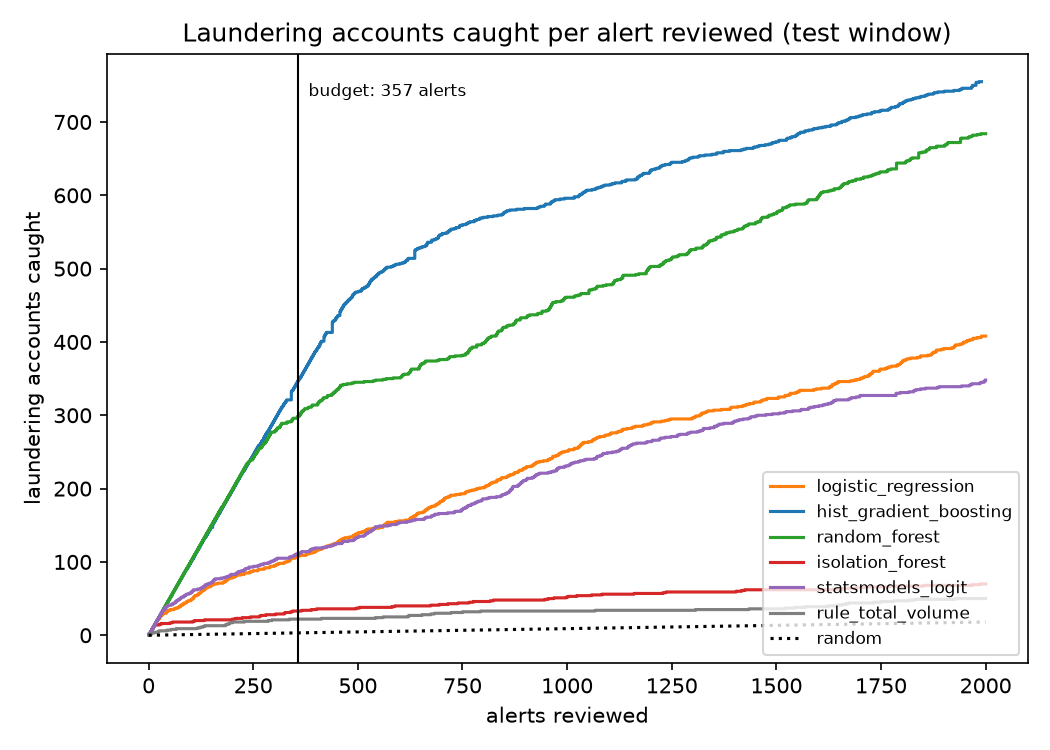

In [3]:
display(Image(REPORTS / 'figures' / 'alert_capacity.png'))

At the budget, gradient boosting catches almost one laundering account per alert. The random forest
is close up to ~250 alerts and then falls behind. The linear models catch about a third as many, and the
total-volume rule, a reasonable-sounding first rule, catches fewer than the unsupervised model.

## Sensitivity to the budget

In [4]:
scores = con.sql("select model, score, is_suspicious from ml.model_scores").df()
rows = []
for budget in [100, 250, 357, 500, 1000, 2000]:
    for model, g in scores.groupby("model"):
        r = best_cutoff(g.score.to_numpy(), g.is_suspicious.to_numpy(), budget)
        rows.append({"budget": budget, "model": model, "caught": r.caught, "precision": round(r.precision, 3)})
pd.DataFrame(rows).pivot(index="model", columns="budget", values="caught").sort_values(357, ascending=False)

budget,100,250,357,500,1000,2000
model,,,,,,
hist_gradient_boosting,99,246,347,468,596,755
random_forest,100,242,299,345,461,684
statsmodels_logit,58,93,111,134,231,348
logistic_regression,48,88,108,139,251,408
isolation_forest,18,25,33,37,52,70
rule_total_volume,9,19,22,23,33,50


Doubling capacity from 357 to ~700 alerts adds far fewer catches than the first 357 did:
precision drops as the model works through less obvious cases. That trade-off is the conversation
to have with an investigations manager.

## Who gets flagged

In [5]:
con.sql("""
select s.account_id, round(s.score, 4) as score, s.is_suspicious,
       f.tx_count, f.fan_out, f.fan_in, round(f.share_ach, 2) as share_ach,
       round(f.share_cross_bank, 2) as share_cross_bank, round(f.flow_balance, 2) as flow_balance
from ml.model_scores s
join marts.fct_account_features f using (account_id, window_start)
where s.model = 'hist_gradient_boosting' and s.flagged = 1
order by s.score desc
limit 15
""").df()

,account_id,score,is_suspicious,tx_count,fan_out,fan_in,share_ach,share_cross_bank,flow_balance
0,0221032-80FBC0EE0,0.9961,1,4,1,1,1.00,0.60,1.00
1,021611-8051B3BF0,0.9956,1,5,2,2,1.00,0.67,0.42
2,01588-80255E6A0,0.9956,1,5,3,1,1.00,0.67,0.39
3,0116904-8064A8D40,0.9955,1,6,2,1,1.00,0.71,0.63
4,0238845-80F499130,0.9954,1,6,3,2,0.86,0.71,0.46
5,070-100428810,0.9954,1,8417,1061,56,0.00,1.00,0.00
6,0232304-80C2E5A90,0.9953,1,4,3,0,0.80,0.40,0.12
7,011-8002785A0,0.9953,1,5,2,1,0.83,0.67,0.42
8,022758-802716DD0,0.9953,1,4,2,1,1.00,0.60,0.87
9,0218755-80DA98640,0.9953,1,4,3,0,1.00,0.60,0.47


Most top alerts are small accounts with a handful of transfers, mostly ACH and cross-bank, passing
money through: the profile of intermediary ("mule") accounts in the simulated typologies. Laundering is
typically only a quarter of their transfers, so the model is reading the shape of the activity, not the
label.

**Caveat:** this is synthetic data. Simulated launderers follow a few clean typologies, which makes them
easier to separate than in real banks. The pipeline and evaluation method carry over; the exact catch
rate would not.